# Jak działa ChatGPT? Duże modele językowe w pigułce

**Plan notatnika:**
1. Czym jest duży model językowy (LLM)
2. Mini-model językowy: jak model „losuje” kolejne słowa
3. Jak model rozumie kontekst: Transformer i mechanizm uwagi
4. Jak powstaje ChatGPT
5. Jak korzystać z LLM w praktyce
6. Ograniczenia i podsumowanie

**Cel:** zrozumieć **na poziomie intuicji**, jak działa ChatGPT i podobne narzędzia, i zobaczyć na bardzo małym przykładzie, na czym polega ich główna sztuczka. Nie będzie tu wzorów ani budowania prawdziwych modeli - one mają miliardy parametrów i wymagają ogromnych komputerów.

## 1. Czym jest duży model językowy (LLM)

Weźmy podpowiedzi w telefonie: piszesz „Dzień dob…” i telefon proponuje „dobry”. **Duży model językowy** (*Large Language Model*, LLM) działa na tej samej zasadzie, tylko w nieporównywalnie większej skali:

> **LLM to bardzo zaawansowane „autouzupełnianie”: na podstawie dotychczasowego tekstu ocenia, jakie słowo najlepiej pasuje jako następne.**

Odpowiedź ChatGPT powstaje krok po kroku:
1. model dostaje Twoje pytanie,
2. ocenia, które słowa mogą być następne, i każdemu przypisuje **prawdopodobieństwo**,
3. **losuje** jedno z nich (częściej te bardziej prawdopodobne),
4. dokleja je do tekstu i wraca do punktu 2, aż odpowiedź będzie gotowa.

Z tego jednego prostego zadania wynikają wszystkie umiejętności modelu: pisanie tekstów, tłumaczenie, streszczanie, a nawet pisanie kodu.

**Token** - model nie operuje dokładnie na słowach, tylko na **tokenach**: kawałkach tekstu (całe słowo, część słowa lub znak interpunkcyjny). W tym notatniku dla prostoty będziemy mówić o słowach.

**Czego model uczy się w treningu?** Czytając ogromne ilości tekstu (internet, książki, kod), uczy się, **co zwykle występuje po czym** i w jakim kontekście. Nie ma w nim bazy faktów, a jedynie wzorce językowe zapisane w miliardach liczb (*parametrów*).

## 2. Mini-model językowy: jak model „losuje” kolejne słowa

Zbudujemy najprostszy możliwy model językowy. Dostanie kilkanaście krótkich zdań o analizie danych i policzy, **jakie słowa najczęściej występowały po jakich**. To całe „uczenie”.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

corpus = [
    "model uczy się na danych treningowych",
    "model przewiduje wynik na danych testowych",
    "analityk ocenia model na danych testowych",
    "analityk przygotowuje dane treningowe",
    "model uczy się wzorców w danych",
    "analityk ocenia wynik modelu",
    "model przewiduje wynik",
    "model jest zbyt prosty",
    "model jest przeuczony",
    "model wymaga danych",
    "model dobrze generalizuje",
    "analityk wybiera model",
]

# zliczamy, jakie słowa występowały po danym słowie (<s> = początek zdania, </s> = koniec)
counts = defaultdict(Counter)
for sentence in corpus:
    words = ["<s>"] + sentence.split() + ["</s>"]
    for current, following in zip(words[:-1], words[1:]):
        counts[current][following] += 1

def next_word_probs(word):
    c = counts[word]
    total = sum(c.values())
    return {w: n / total for w, n in c.items()}

pd.Series(next_word_probs("model")).sort_values(ascending=False).round(2)

uczy          0.2
przewiduje    0.2
jest          0.2
na            0.1
wymaga        0.1
dobrze        0.1
</s>          0.1
dtype: float64

Po słowie „model” nasz mini-model „wie”, że najczęściej pojawiały się „uczy”, „przewiduje” i „jest”, a rzadziej „wymaga” czy „dobrze”. Prawdziwy LLM robi to samo, ale bierze pod uwagę **cały dotychczasowy tekst** (nawet kilkaset stron), a nie tylko jedno poprzednie słowo.

### Generowanie tekstu
Teraz możemy „napisać” zdanie: zaczynamy od początku zdania i **losujemy** kolejne słowa zgodnie z prawdopodobieństwami, aż trafimy na koniec zdania.

In [10]:
def generate(rng, probs_fn=next_word_probs):
    word, result = "<s>", []
    while len(result) < 10:
        probs = probs_fn(word)
        word = rng.choice(list(probs), p=list(probs.values()))
        if word == "</s>":
            break
        result.append(str(word))
    return " ".join(result)

rng = np.random.default_rng(5)
for _ in range(5):
    print(generate(rng))

analityk wybiera model przewiduje wynik modelu
model uczy się wzorców w danych
analityk wybiera model na danych treningowych
model dobrze generalizuje
analityk ocenia wynik


Część zdań brzmi sensownie, a część to **nowe kombinacje**, których nie było w danych treningowych (np. „analityk wybiera model na danych treningowych”). Widać też ograniczenie: model zna tylko jedno poprzednie słowo, więc niektóre zdania są pozbawione sensu. Tak działają też LLM, tylko znacznie lepiej, bo „pamiętają” cały kontekst.

### Parametr `temperature` (kreatywność)
W API ChatGPT i innych modeli jest parametr **temperature**, który mówi, jak odważnie model ma losować:
- **niska** - model wybiera niemal zawsze najbardziej prawdopodobne słowa (odpowiedzi powtarzalne, zachowawcze),
- **wysoka** - model częściej sięga po mniej prawdopodobne słowa (odpowiedzi różnorodne, ale mniej przewidywalne).

Zobaczmy, jak zmienia to prawdopodobieństwa po słowie „model”.

In [11]:
def with_temperature(probs, T):
    words = list(probs)
    logits = np.log([probs[w] for w in words])
    scaled = np.exp(logits / T)
    return dict(zip(words, scaled / scaled.sum()))

table = pd.DataFrame({f"temperature={T}": with_temperature(next_word_probs("model"), T)
                      for T in [0.2, 1.0, 2.0]})
table.round(2)

,temperature=0.2,temperature=1.0,temperature=2.0
uczy,0.32,0.2,0.17
przewiduje,0.32,0.2,0.17
na,0.01,0.1,0.12
jest,0.32,0.2,0.17
wymaga,0.01,0.1,0.12
dobrze,0.01,0.1,0.12
</s>,0.01,0.1,0.12


Przy niskiej temperaturze prawdopodobieństwa skupiają się na kilku najczęstszych słowach, a przy wysokiej wyrównują się. Sprawdźmy, jak to wpływa na generowane zdania: dla każdej temperatury losujemy 30 zdań i liczymy, ile z nich jest **różnych**.

In [12]:
for T in [0.2, 1.0, 2.0]:
    rng = np.random.default_rng(42)
    sentences = [generate(rng, lambda w: with_temperature(next_word_probs(w), T)) for _ in range(30)]
    print(f"temperature={T}: {len(set(sentences))} różnych zdań na 30 wylosowanych")

temperature=0.2: 11 różnych zdań na 30 wylosowanych
temperature=1.0: 18 różnych zdań na 30 wylosowanych
temperature=2.0: 19 różnych zdań na 30 wylosowanych


Im wyższa temperatura, tym więcej różnorodności (ale też więcej nielogicznych zdań). Dlatego **ten sam prompt może za każdym razem dać inną odpowiedź**.

**Jak to wykorzystać:** niską temperaturę ustawiamy tam, gdzie liczy się powtarzalność (kod, wyciąganie danych z tekstu), a wyższą przy zadaniach kreatywnych (pomysły, slogany).

## 3. Jak model rozumie kontekst: Transformer i mechanizm uwagi

Nasz mini-model patrzy tylko na jedno poprzednie słowo. Prawdziwe LLM są zbudowane z architektury **Transformer** (2017 r.), której kluczowym pomysłem jest **mechanizm uwagi** (*attention*): przy każdym słowie model sprawdza, **na które inne słowa w tekście powinien zwrócić uwagę**.

Weźmy zdanie:

> *Robot nie mógł podnieść walizki, bo **była** ciężka.*

Żeby zrozumieć słowo „była”, trzeba wiedzieć, że chodzi o **walizkę**, a nie o robota. Dobrze wytrenowany model przy słowie „była” przypisze największą „uwagę” słowu „walizki”. Poniżej **ilustracja** takiego rozkładu uwagi (wagi ustawiliśmy ręcznie, żeby pokazać ideę; w prawdziwym modelu są wyliczane automatycznie i wynikają z treningu).

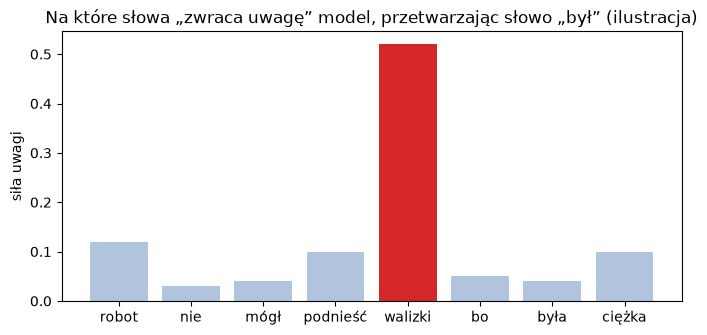

In [14]:
tokens = ["robot", "nie", "mógł", "podnieść", "walizki", "bo", "była", "ciężka"]
attention = [0.12, 0.03, 0.04, 0.10, 0.52, 0.05, 0.04, 0.10]   # ilustracja, suma = 1

plt.figure(figsize=(8, 3.5))
plt.bar(tokens, attention, color=["tab:red" if t == "walizki" else "lightsteelblue" for t in tokens])
plt.title('Na które słowa „zwraca uwagę” model, przetwarzając słowo „był” (ilustracja)')
plt.ylabel("siła uwagi")
plt.show()

Co z tego wynika w praktyce:
- Model **widzi cały kontekst naraz** i potrafi powiązać odległe słowa (np. zaimek z rzeczownikiem z początku akapitu). Starsze sieci czytały tekst słowo po słowie i „zapominały” początek.
- Taka uwaga jest liczona **wielokrotnie, w wielu „warstwach” i „głowach”**: jedne wychwytują gramatykę, inne znaczenie, jeszcze inne np. powiązania w kodzie.
- Model GPT to **kilkadziesiąt takich warstw ułożonych jedna na drugiej**, z miliardami parametrów. Wszystkie są uczone tak jak w sieciach z poprzednich rozdziałów: model zgaduje następne słowo, porównuje z prawdziwym i poprawia swoje parametry.

Litera **T** w GPT pochodzi właśnie od słowa *Transformer* (*Generative Pre-trained Transformer*).

## 4. Jak powstaje ChatGPT

ChatGPT nie powstał w jednym kroku. Można to porównać do nauki człowieka:

| Etap | Analogia | Co się dzieje |
|---|---|---|
| **1. Trening wstępny** (*pre-training*) | czytanie ogromnej liczby książek i stron internetowych | model uczy się języka i wiedzy o świecie, przewidując następne słowo. Powstaje **model bazowy**, który potrafi kontynuować tekst, ale jeszcze nie prowadzi rozmowy. Ten etap jest najdroższy |
| **2. Uczenie na przykładach rozmów** (*SFT*) | nauka od nauczyciela na wzorcowych odpowiedziach | ludzie piszą tysiące par „polecenie - dobra odpowiedź”. Model uczy się wykonywać polecenia, a nie tylko dokańczać tekst |
| **3. Uczenie na ocenach ludzi** (*RLHF*) | informacja zwrotna: „ta odpowiedź jest lepsza” | ludzie oceniają i porównują odpowiedzi modelu. Model uczy się tych, które są pomocne, prawdziwe i bezpieczne |

Dlatego ChatGPT zachowuje się jak asystent, a nie jak „wyszukiwarka tekstu”. Etapy 2 i 3 wymagają znacznie mniej danych niż etap 1, ale ich jakość mocno wpływa na to, jak model się zachowuje.

## 5. Jak korzystać z LLM w praktyce

- **Czat lub API** - najczęstszy sposób: wysyłamy **prompt** (polecenie), dostajemy odpowiedź. Jakość zależy od tego, jak dobrze opiszemy zadanie, a odpowiedź kontrolujemy też parametrami (np. `temperature`).
- **Okno kontekstu** - model „pamięta” tylko ograniczoną ilość tekstu (prompt + odpowiedź). Bardzo długich dokumentów nie zobaczy w całości.
- **RAG** (*Retrieval-Augmented Generation*) - zamiast liczyć na to, co model zapamiętał, najpierw **wyszukujemy** fragmenty własnych dokumentów, a potem **wklejamy je do promptu** razem z pytaniem. Dzięki temu model może odpowiadać na podstawie aktualnych i firmowych danych, a rzadziej zmyśla.
- **Dotrenowanie modelu** (*fine-tuning*) - dalsze uczenie modelu na własnych przykładach, np. by pisał w określonym stylu. Używane rzadziej niż prompt i RAG, bo jest droższe.
- **Modele otwarte** (np. LLaMA, Mistral) można uruchomić na własnym sprzęcie, co daje większą kontrolę nad danymi, ale wymaga mocnego komputera.

## 6. Ograniczenia i podsumowanie

**Ograniczenia, o których trzeba pamiętać:**
- **Halucynacje** - model potrafi z pełnym przekonaniem podać nieprawdziwe informacje (np. nieistniejące funkcje bibliotek lub źródła), bo wybiera tekst **prawdopodobny**, a nie **prawdziwy**.
- **Brak gwarancji poprawności** - model nie „wie”, czy ma rację, i nie sprawdza faktów ani obliczeń (chyba że ma do tego dodatkowe narzędzia).
- **Ograniczona wiedza** - zna świat tylko do momentu zakończenia treningu; o nowszych rzeczach wie tyle, ile podamy w prompcie.
- **Uprzedzenia** - model powiela wzorce (także stereotypy) z danych, na których się uczył.
- **Losowość** - ta sama prośba może dać różne odpowiedzi.
- **Prywatność** - prompt zwykle opuszcza komputer, więc **nie wysyłamy danych poufnych i osobowych**.

**W pigułce:**
1. LLM to zaawansowane **autouzupełnianie**: na podstawie dotychczasowego tekstu **losuje kolejne słowa** zgodnie z wyliczonymi prawdopodobieństwami.
2. **Mechanizm uwagi** (Transformer) pozwala modelowi uwzględniać cały kontekst, a nie tylko ostatnie słowo.
3. ChatGPT powstaje w trzech etapach: **czytanie ogromu tekstów**, **nauka wykonywania poleceń**, **dopasowanie do ocen ludzi**.
4. Wynik zależy od promptu i parametrów, a jego poprawność **zawsze trzeba sprawdzić**.